# Phase 1 — SPY Market Data & Financial Time Series EDA

**Research purpose:** inspect the fixed SPY snapshot and understand financial returns before training models.

- Data processing, features, labels, and splits are implemented in `src/quant_trading/`.
- This notebook reads outputs from the pipeline; it does **not** redownload prices or rebuild labels.
- **Exploratory analysis uses the training period (2005–2018) only.** The validation and test periods remain reserved for later experiments.
- Figures and diagnostics below are descriptive, **not** evidence of predictive power or trading profitability.

Run these commands from the repository root first:

```bash
python -m pip install -e ".[dev,research]"
python -m quant_trading.pipeline
jupyter lab
```

## 1. Load reproducible data and metadata

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss

current_dir = Path.cwd().resolve()
for PROJECT_ROOT in (current_dir, *current_dir.parents):
    if (PROJECT_ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")

raw_path = PROJECT_ROOT / "data/raw/spy_daily.parquet"
processed_dir = PROJECT_ROOT / "data/processed"

required_paths = [
    raw_path,
    processed_dir / "spy_train.parquet",
    processed_dir / "spy_features.parquet",
    processed_dir / "manifest.json",
]
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Run 'python -m quant_trading.pipeline' first. Missing: "
        + ", ".join(missing)
    )

spy = pd.read_parquet(raw_path)
train = pd.read_parquet(processed_dir / "spy_train.parquet")
features = pd.read_parquet(processed_dir / "spy_features.parquet")
manifest = json.loads((processed_dir / "manifest.json").read_text(encoding="utf-8"))
feature_columns = manifest["feature_columns"]

assert train.index.max() < pd.Timestamp("2019-01-01")
assert len(feature_columns) == 17

print("Raw rows:", len(spy))
print("Training rows after warm-up/purging:", len(train))
print("Training date range:", train.index.min().date(), "to", train.index.max().date())
print("Number of features:", len(feature_columns))
print("Raw data SHA256:", manifest["raw_sha256"])
display(train.head(3))

Raw rows: 5492
Training rows after warm-up/purging: 3458
Training date range: 2005-04-05 to 2018-12-27
Number of features: 17
Raw data SHA256: 8f4599139be134c9dfb409394b93b42fc48058a2e19191a68d7a847b63567019


,ret_1d,ret_lag_1,ret_lag_2,ret_lag_5,momentum_5d,momentum_21d,vol_21d,vol_63d,vol_ratio,sma_gap_20,ema_gap_12,ema_gap_26,rsi_14,macd_norm,macd_hist_norm,bb_position,relative_volume_20,entry_date,exit_date,future_return,label
Date,,,,,,,,,,,,,,,,,,,,,
2005-04-05,0.004750,0.001702,-0.004504,-0.006671,0.014145,-0.033773,0.096959,0.102552,0.945464,-0.003384,0.001926,-0.002950,47.336965,-0.004880,-0.000226,-0.136919,0.736768,2005-04-06,2005-04-07,-0.000338,0
2005-04-06,0.003463,0.004750,0.001702,0.014060,0.003547,-0.030799,0.098307,0.099816,0.984886,0.001446,0.004566,0.000471,50.014434,-0.004075,0.000451,0.067921,0.831807,2005-04-07,2005-04-08,0.006419,1
2005-04-07,0.005382,0.003463,0.004750,-0.001863,0.010793,-0.021664,0.100694,0.099363,1.013394,0.007385,0.008438,0.005433,53.950430,-0.002964,0.001230,0.368767,0.745218,2005-04-08,2005-04-11,-0.007385,0


## 2. Market data quality and training sample

Missing values at the beginning of rolling features are expected (warm-up period). They were removed **after** labels were aligned to the original trading calendar. The core pipeline validates the complete OHLCV snapshot against NYSE sessions.

In [2]:
train_prices = spy.loc[:"2018-12-31", "Adj Close"].astype(float)
train_returns = train_prices.pipe(np.log).diff().dropna()
training_features = features.loc[:"2018-12-31", feature_columns]

quality = pd.DataFrame({
    "missing_values": training_features.isna().sum(),
    "first_valid_date": [
        training_features[col].first_valid_index()
        for col in feature_columns
    ],
})
display(quality)

print("Training positive-label rate:", f'{train["label"].mean():.2%}')
print("Training zero/one counts:")
display(train["label"].value_counts().sort_index())

Training positive-label rate: 54.45%
Training zero/one counts:


,missing_values,first_valid_date
ret_1d,1,2005-01-04
ret_lag_1,2,2005-01-05
ret_lag_2,3,2005-01-06
ret_lag_5,6,2005-01-11
momentum_5d,5,2005-01-10
momentum_21d,21,2005-02-02
vol_21d,21,2005-02-02
vol_63d,63,2005-04-05
vol_ratio,63,2005-04-05
sma_gap_20,19,2005-01-31


label
0    1575
1    1883
Name: count, dtype: int64

## 3. Adjusted prices and log returns

The adjusted-close series is a convenient historical total-return proxy. It is not a directly executable price and may be revised after corporate actions.

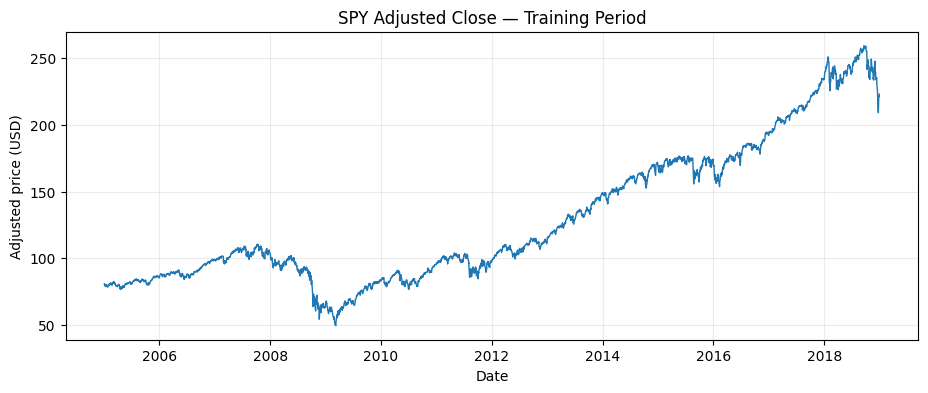

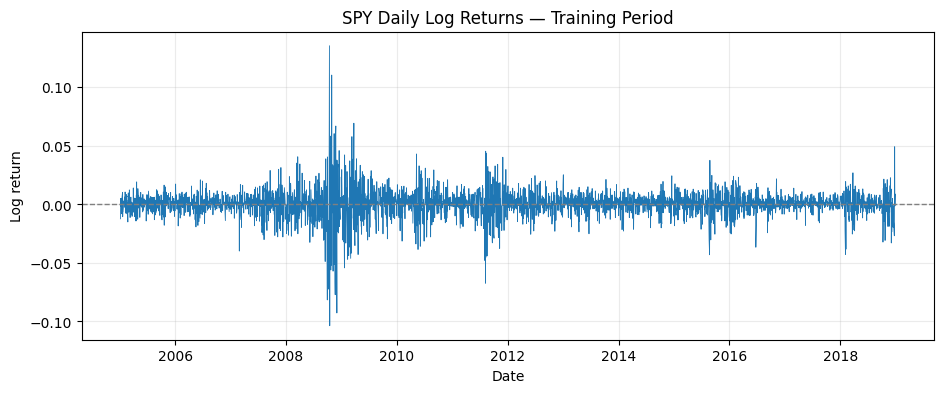

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train_prices.index, train_prices, linewidth=1)
ax.set(title="SPY Adjusted Close — Training Period", xlabel="Date", ylabel="Adjusted price (USD)")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train_returns.index, train_returns, linewidth=0.6)
ax.axhline(0, color="gray", linewidth=1, linestyle="--")
ax.set(title="SPY Daily Log Returns — Training Period", xlabel="Date", ylabel="Log return")
ax.grid(alpha=0.25)
plt.show()

## 4. Return distribution and descriptive statistics

Skewness and excess kurtosis describe historical asymmetry and tail behavior. They do not by themselves demonstrate a stable forecastable signal.

,value
mean,0.000288
std_daily,0.011768
skewness,-0.139087
excess_kurtosis,14.996663
min,-0.103637
max,0.135577
n_observations,3522.000000


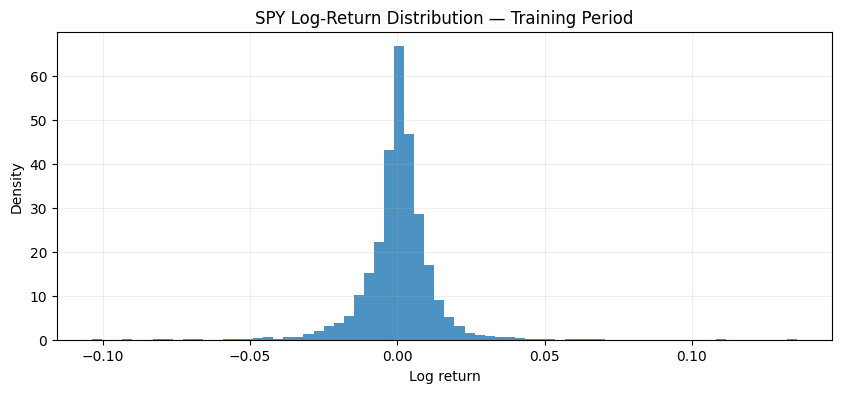

In [4]:
statistics = pd.Series({
    "mean": train_returns.mean(),
    "std_daily": train_returns.std(ddof=1),
    "skewness": train_returns.skew(),
    "excess_kurtosis": train_returns.kurt(),
    "min": train_returns.min(),
    "max": train_returns.max(),
    "n_observations": len(train_returns),
})
display(statistics.to_frame("value"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(train_returns, bins=70, density=True, alpha=0.8)
ax.set(title="SPY Log-Return Distribution — Training Period", xlabel="Log return", ylabel="Density")
ax.grid(alpha=0.2)
plt.show()

## 5. Historical volatility and volatility regimes

Rolling annualized volatility uses the conventional factor $\sqrt{252}$. This is an approximation, not an exact scaling identity under arbitrary return dynamics.

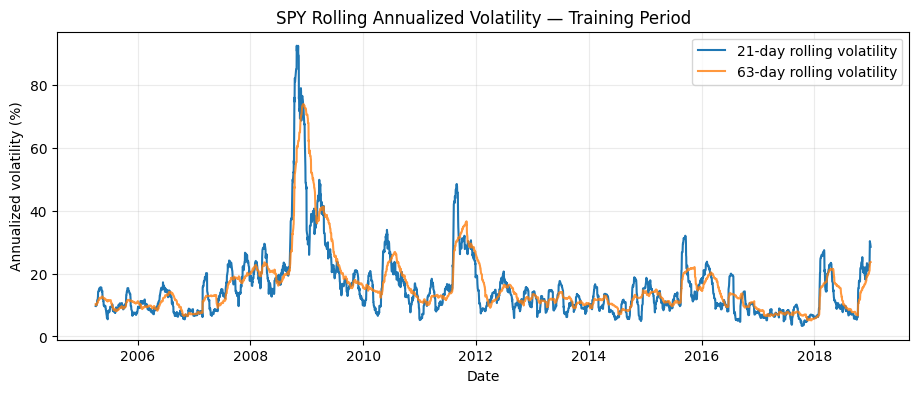

In [5]:
volatility = features.loc[:"2018-12-31", ["vol_21d", "vol_63d"]].dropna()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(volatility.index, 100 * volatility["vol_21d"], label="21-day rolling volatility")
ax.plot(volatility.index, 100 * volatility["vol_63d"], label="63-day rolling volatility", alpha=0.8)
ax.set(title="SPY Rolling Annualized Volatility — Training Period", xlabel="Date", ylabel="Annualized volatility (%)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 6. Autocorrelation diagnostics

The ACF/PACF of returns investigate linear dependence. Autocorrelation in squared returns is a descriptive indicator of volatility clustering; it is not proof of a particular GARCH specification.

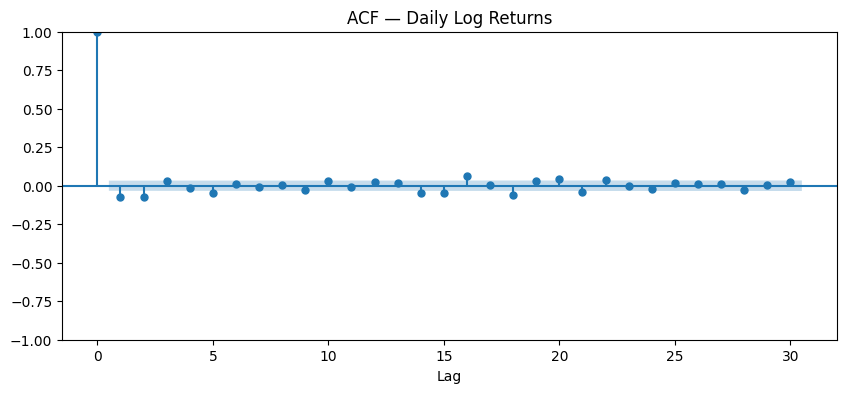

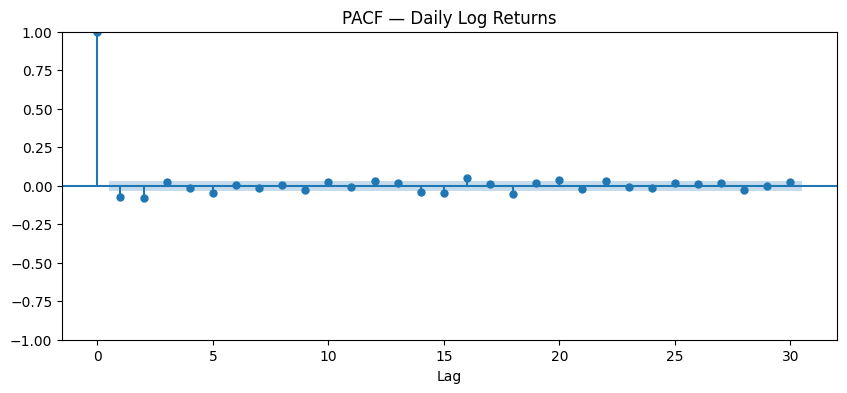

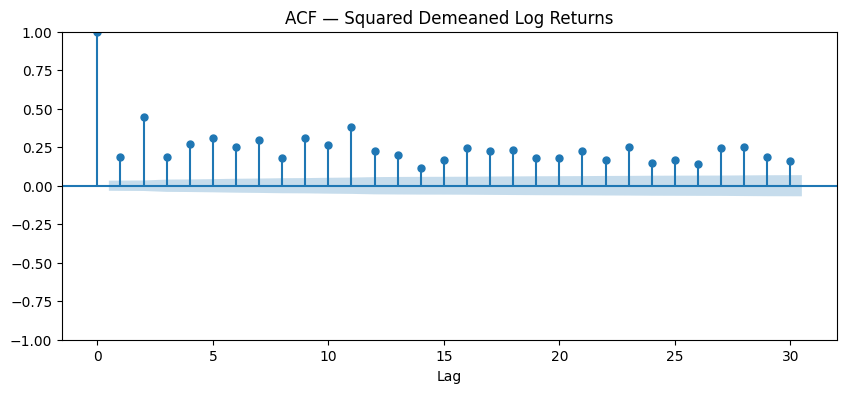

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train_returns, lags=30, alpha=0.05, ax=ax)
ax.set(title="ACF — Daily Log Returns", xlabel="Lag")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train_returns, lags=30, method="ywm", alpha=0.05, ax=ax)
ax.set(title="PACF — Daily Log Returns", xlabel="Lag")
plt.show()

centered_squared_returns = (train_returns - train_returns.mean()) ** 2
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(centered_squared_returns, lags=30, alpha=0.05, ax=ax)
ax.set(title="ACF — Squared Demeaned Log Returns", xlabel="Lag")
plt.show()

## 7. Stationarity and serial-dependence tests

- **ADF null hypothesis:** a unit root is present.
- **KPSS null hypothesis (`regression="c"`):** level stationarity.
- **Ljung–Box null hypothesis:** no serial correlation at the tested lags.

These tests are sensitive to assumptions, structural breaks, heteroskedasticity and choice of lag length. Failure to reject is **not** proof of the null.

In [7]:
from inspect import signature
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning


def stationarity_diagnostics(series, name):
    values = series.dropna()
    # Request the tuple explicitly on versions that offer two result formats.
    adf_options = {"result_object": False} if "result_object" in signature(adfuller).parameters else {}
    kpss_options = {"result_object": False} if "result_object" in signature(kpss).parameters else {}
    adf = adfuller(values, regression="c", autolag="AIC", **adf_options)
    with warnings.catch_warnings():
        # Show the direction of the table bound in the result itself.
        warnings.filterwarnings("ignore", message="The test statistic is outside of the range.*",
                                category=InterpolationWarning)
        stat, pvalue, _, critical = kpss(values, regression="c", nlags="auto", **kpss_options)
    if stat > critical["1%"]:
        kpss_p = "< 0.01"
    elif stat < critical["10%"]:
        kpss_p = "> 0.10"
    else:
        kpss_p = f"{pvalue:.4g}"
    return {"Series": name, "ADF stat": adf[0], "ADF p": f"{adf[1]:.4g}",
            "KPSS stat": stat, "KPSS p": kpss_p}


diagnostics = pd.DataFrame([
    stationarity_diagnostics(np.log(train_prices), "Log prices"),
    stationarity_diagnostics(train_returns, "Log returns"),
])
print("Stationarity tests")
print(diagnostics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

for name, series in [("log returns", train_returns),
                     ("squared demeaned log returns", centered_squared_returns)]:
    result = acorr_ljungbox(series, lags=[5, 10, 20], return_df=True).rename_axis("lag")
    print(f"\nLjung-Box — {name}")
    print(result.to_string(formatters={
        "lb_stat": lambda x: f"{x:.4f}",
        "lb_pvalue": lambda p: "< 1e-300" if p < 1e-300 else f"{p:.4g}",
    }))

Stationarity tests
     Series  ADF stat     ADF p  KPSS stat KPSS p
 Log prices   -0.2869    0.9273     7.7137 < 0.01
Log returns  -12.5069 2.728e-23     0.1363 > 0.10

Ljung-Box — log returns
     lb_stat lb_pvalue
lag                   
5    52.7308  3.82e-10
10   58.7018 6.375e-09
20  114.2495 3.277e-15

Ljung-Box — squared demeaned log returns
      lb_stat lb_pvalue
lag                    
5   1549.7770  < 1e-300
10  2791.4450  < 1e-300
20  4581.2814  < 1e-300


## 8. Feature redundancy — train only

Highly correlated indicators may encode similar price movements. This analysis informs model interpretation, but does not justify feature selection using future validation or test outcomes.

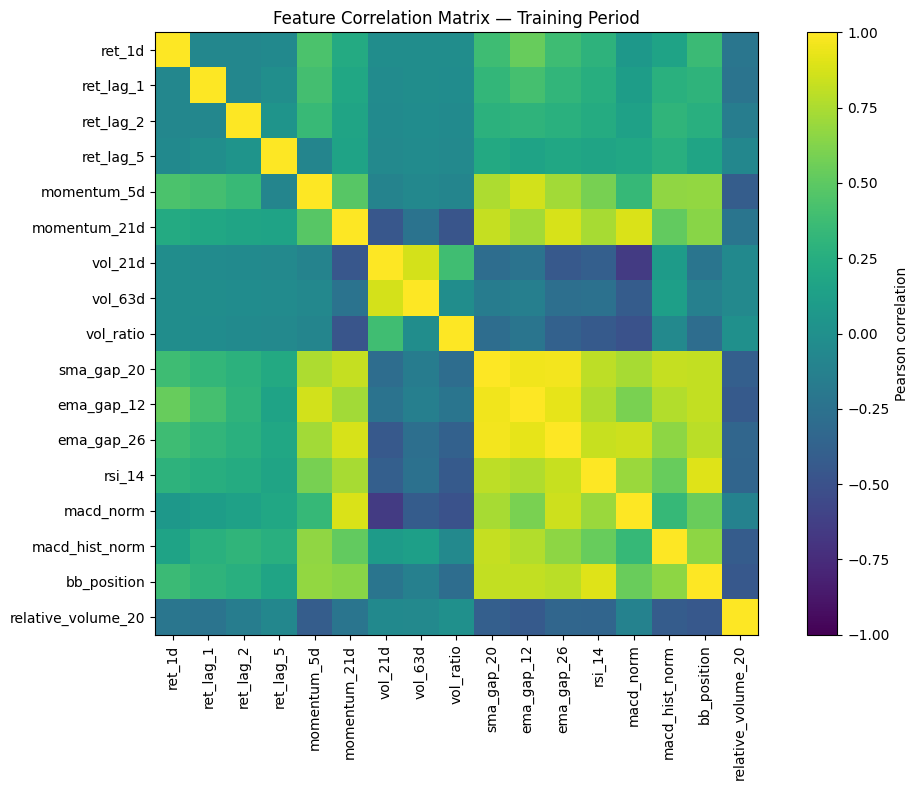

In [8]:
correlation = train[feature_columns].corr()
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(correlation, vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(feature_columns)), labels=feature_columns, rotation=90)
ax.set_yticks(np.arange(len(feature_columns)), labels=feature_columns)
ax.set_title("Feature Correlation Matrix — Training Period")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

## 9. Target and label availability

For a signal formed after close $t$, the holding period runs from open $t+1$ to open $t+2$. The research target uses an adjusted-open proxy computed with closing-price adjustment factors. The exit open marks the economic endpoint. The exact vendor-adjusted label can require end-of-day inputs and may be revised later. The split purge requires the exit session to precede the next evaluation signal. Phase 4 uses this same proxy for the backtest.

In [9]:
assert (train["entry_date"] > train.index.to_series()).all()
assert (train["exit_date"] > train["entry_date"]).all()
assert train[feature_columns].notna().all().all()
assert train["label"].isin([0, 1]).all()

first_five = train[["entry_date", "exit_date", "future_return", "label"]].head(5)
display(first_five)
print("Temporal alignment and feature completeness checks passed.")

Temporal alignment and feature completeness checks passed.


,entry_date,exit_date,future_return,label
Date,,,,
2005-04-05,2005-04-06,2005-04-07,-0.000338,0
2005-04-06,2005-04-07,2005-04-08,0.006419,1
2005-04-07,2005-04-08,2005-04-11,-0.007385,0
2005-04-08,2005-04-11,2005-04-12,-0.003381,0
2005-04-11,2005-04-12,2005-04-13,0.005683,1


## Research notes

**What this notebook does not do:**

- No model training, threshold tuning, trading backtest or test-set exploration.
- ACF/ADF/KPSS results cannot establish profitable predictability.
- Vendor-adjusted prices are a reproducible snapshot, not a verified point-in-time feed.

**Next:** Phase 2 fits Logistic Regression and XGBoost on purged chronological folds. Keep the validation and test periods isolated until their prescribed evaluation stages.

## What the training sample shows

The training set contains 3,458 complete labelled signals with 17 features. The positive class accounts for 54.45%. The price series provides 3,522 close-to-close daily log returns before the feature warm-up and label purge. Their daily standard deviation is 1.18% and their excess kurtosis is 15.00, indicating heavy tails in this sample.

At the 5% level, the ADF and KPSS results are consistent with a unit root in log prices and level stationarity in log returns. KPSS reports boundary p-values from its lookup table. Ljung–Box rejects zero serial correlation through lag 20 for both returns and squared demeaned returns. The latter supports volatility clustering. These tests describe close-to-close returns. Predicting the sign of the next open-to-open return is a separate question addressed by the following notebooks.